In [16]:
# ==============================
# Cell 1: Setup & Config
# ==============================
import os, gc, math, json, random, pathlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Paths
DATA_DIR = Path(".")  # adjust if needed
TRAIN_PATH = DATA_DIR / "/kaggle/input/intelecta-cup-data-mining-competition/train.csv"
TEST_PATH  = DATA_DIR / "/kaggle/input/intelecta-cup-data-mining-competition/test.csv"
SUB_PATH   = DATA_DIR / "/kaggle/input/intelecta-cup-data-mining-competition/sample_submission.csv"

# Parameters
TARGET = "Suhu_Rata_Rata_C"
ID_COL = "ID"
SEED   = 42
EPS    = 0.5  # epsilon for stabilized MAPE
EPS_WEIGHT = 1.0  # for sample_weight = 1/max(|y|, EPS_WEIGHT)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)

set_seed(SEED)
print("Configured. DATA_DIR =", DATA_DIR.resolve())


Configured. DATA_DIR = /kaggle/working


In [17]:
# ==============================
# Cell 2: Load Data
# ==============================
train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)
sub   = pd.read_csv(SUB_PATH)

print("train:", train.shape, "| test:", test.shape)
display(train.head())
display(test.head())


train: (8000, 15) | test: (2000, 14)


,ID,Tahun,Nama_Negara,Wilayah,Jenis_Tanaman,Total_Curah_Hujan_mm,Emisi_CO2_JT_Ton,Hasil_Panen_Ton_per_HA,Kejadian_Cuaca_Ekstrim,Akses_Irigasi,Penggunaan_Pestisida_KG_per_HA,Penggunaan_Pupuk_KG_per_HA,Indeks_Kesehatan_Tanah,Strategi_Adaptasi,Suhu_Rata_Rata_C
0,0,2015,USA,South,Soybeans,1658.71,13.36,2.620,10,74.41,38.97,2.64,46.07,Manajemen Air,20.43
1,1,2022,China,East,Wheat,1478.74,9.55,0.570,2,36.90,49.99,77.22,88.87,Rotasi Tanaman,-0.33
2,2,2000,India,'West Bengal',Fruits,1252.34,27.37,2.115,3,34.21,2.75,83.94,77.15,Pertanian Organik,12.97
3,3,2008,Nigeria,'North West',Sugarcane,209.89,16.16,4.158,5,91.74,36.80,37.50,73.59,Pertanian Organik,12.81
4,4,1991,Canada,Ontario,Vegetables,1086.67,3.71,2.430,0,14.72,7.22,28.72,41.90,Tanpa Adaptasi,4.22


,ID,Tahun,Nama_Negara,Wilayah,Jenis_Tanaman,Total_Curah_Hujan_mm,Emisi_CO2_JT_Ton,Hasil_Panen_Ton_per_HA,Kejadian_Cuaca_Ekstrim,Akses_Irigasi,Penggunaan_Pestisida_KG_per_HA,Penggunaan_Pupuk_KG_per_HA,Indeks_Kesehatan_Tanah,Strategi_Adaptasi
0,8000,2022,Russia,Central,Fruits,1173.04,10.29,2.440,3,59.17,29.17,80.06,74.93,Tanpa Adaptasi
1,8001,1993,Brazil,South,Rice,310.08,13.90,3.276,2,60.59,4.76,70.63,97.59,Tanpa Adaptasi
2,8002,1998,India,Maharashtra,Soybeans,1348.17,12.90,2.620,3,90.93,5.95,63.87,74.81,Tanaman Tahan Kekeringan
3,8003,2010,Russia,Volga,Soybeans,1732.43,23.82,3.717,4,35.11,7.49,81.81,87.01,Rotasi Tanaman
4,8004,1998,Canada,'British Columbia',Sugarcane,2242.77,28.92,2.034,6,68.75,43.35,48.14,64.22,Manajemen Air


Columns: ['ID', 'Tahun', 'Nama_Negara', 'Wilayah', 'Jenis_Tanaman', 'Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Hasil_Panen_Ton_per_HA', 'Kejadian_Cuaca_Ekstrim', 'Akses_Irigasi', 'Penggunaan_Pestisida_KG_per_HA', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah', 'Strategi_Adaptasi', 'Suhu_Rata_Rata_C']
Target zero count: 0
Target negative count: 971


,Suhu_Rata_Rata_C
count,8000.000000
mean,15.206680
std,11.490611
min,-4.990000
1%,-4.560100
5%,-2.880000
25%,5.377500
50%,15.140000
75%,25.340000
95%,32.990000


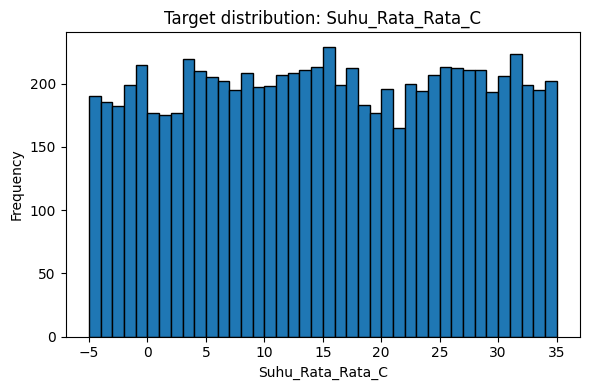

In [18]:
# ==============================
# Cell 3: Quick Target & Columns Check
# ==============================
assert TARGET in train.columns, f"Target '{TARGET}' not found in train."
print("Columns:", list(train.columns))
print("Target zero count:", (train[TARGET]==0).sum())
print("Target negative count:", (train[TARGET]<0).sum())

# Summary stats
display(train[[TARGET]].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]))

plt.figure(figsize=(6,4))
train[TARGET].plot(kind="hist", bins=40, edgecolor="black")
plt.title(f"Target distribution: {TARGET}")
plt.xlabel(TARGET); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()


In [19]:
# ==============================
# Cell 4: Utility - MAPE with epsilon
# ==============================
from sklearn.metrics import make_scorer

def mape_eps(y_true, y_pred, eps=EPS):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.maximum(np.abs(y_true), eps)
    return np.mean(np.abs(y_true - y_pred) / denom) * 100.0

mape_scorer = make_scorer(lambda yt, yp: -mape_eps(yt, yp))  # for sklearn (higher is better -> negative)
print("Test mape_eps:", mape_eps([1,2,3],[1,2,4]))


Test mape_eps: 11.11111111111111


In [20]:
# ==============================
# Cell 5: Basic Dtypes & Column Lists
# ==============================
cat_cols = train.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in train.columns if c not in [TARGET, ID_COL] and c not in cat_cols]

print("Categorical columns:", cat_cols)
print("Numeric columns:", num_cols)


Categorical columns: ['Nama_Negara', 'Wilayah', 'Jenis_Tanaman', 'Strategi_Adaptasi']
Numeric columns: ['Tahun', 'Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Hasil_Panen_Ton_per_HA', 'Kejadian_Cuaca_Ekstrim', 'Akses_Irigasi', 'Penggunaan_Pestisida_KG_per_HA', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah']


In [21]:
# ==============================
# Cell 6: Imputation (median per Negara for numeric; UNK for categorical)
# ==============================
GROUP_COL = "Nama_Negara" if "Nama_Negara" in train.columns else None

def group_median_impute(df_train, df_test, cols, group_col):
    if group_col is None:
        for c in cols:
            med = df_train[c].median()
            df_train[c] = df_train[c].fillna(med)
            df_test[c]  = df_test[c].fillna(med)
        return df_train, df_test
    
    med_map = df_train.groupby(group_col)[cols].median()
    for c in cols:
        df_train[c] = df_train[c].fillna(df_train[group_col].map(med_map[c]))
        df_train[c] = df_train[c].fillna(df_train[c].median())
        df_test[c]  = df_test[c].fillna(df_test[group_col].map(med_map[c]))
        df_test[c]  = df_test[c].fillna(df_train[c].median())
    return df_train, df_test

train, test = group_median_impute(train, test, num_cols, GROUP_COL)

for c in cat_cols:
    train[c] = train[c].fillna("UNK")
    test[c]  = test[c].fillna("UNK")

print("Imputation done.")


Imputation done.


In [22]:
# ==============================
# Cell 7 (FIXED): Winsorize per group
# ==============================
def winsorize_per_group(df, cols, group_col=None, p_low=0.02, p_high=0.98):
    df = df.copy()
    if not cols:
        return df
    if group_col is None or group_col not in df.columns:
        lo_glob = df[cols].quantile(p_low)
        hi_glob = df[cols].quantile(p_high)
        for c in cols:
            df[c] = np.clip(df[c], lo_glob[c], hi_glob[c])
        return df
    for c in cols:
        s_lo = df.groupby(group_col)[c].quantile(p_low)
        s_hi = df.groupby(group_col)[c].quantile(p_high)
        glo = df[c].quantile(p_low)
        ghi = df[c].quantile(p_high)
        lo = df[group_col].map(s_lo).fillna(glo)
        hi = df[group_col].map(s_hi).fillna(ghi)
        df[c] = np.clip(df[c].values, lo.values, hi.values)
    return df

train = winsorize_per_group(train, num_cols, GROUP_COL, 0.02, 0.98)
print("Winsorizing done.")


Winsorizing done.


In [23]:
# ==============================
# Cell A1: Transform & cap hasil panen
# ==============================
PANEN = "Hasil_Panen_Ton_per_HA"
if PANEN in train.columns:
    for df in [train, test]:
        if "Nama_Negara" in df.columns:
            q1 = df.groupby("Nama_Negara")[PANEN].quantile(0.01)
            q9 = df.groupby("Nama_Negara")[PANEN].quantile(0.99)
            lo = df["Nama_Negara"].map(q1).fillna(train[PANEN].quantile(0.01))
            hi = df["Nama_Negara"].map(q9).fillna(train[PANEN].quantile(0.99))
            df[PANEN] = np.clip(df[PANEN].values, lo.values, hi.values)
        else:
            lo = train[PANEN].quantile(0.01); hi = train[PANEN].quantile(0.99)
            df[PANEN] = np.clip(df[PANEN].values, lo, hi)
        shift = max(1e-6, float((train[PANEN].min() <= 0)) * (abs(train[PANEN].min()) + 1e-3))
        df[PANEN+"_log"] = np.log1p(df[PANEN] + shift)

    use_panen_log_only = True
    if use_panen_log_only:
        train.drop(columns=[PANEN], errors="ignore", inplace=True)
        test.drop(columns=[PANEN], errors="ignore", inplace=True)

print("Panen transformed (log) and capped.")


Panen transformed (log) and capped.


In [24]:
# ==============================
# Cell 8: Time features & simple interactions
# ==============================
if "Tahun" in train.columns:
    train["Tahun2"] = train["Tahun"]**2
    test["Tahun2"]  = test["Tahun"]**2

def add_interactions(df):
    cols = []
    if {"Akses_Irigasi","Total_Curah_Hujan_mm"}.issubset(df.columns):
        df["Irigasi_x_Hujan"] = df["Akses_Irigasi"] * df["Total_Curah_Hujan_mm"]
        cols.append("Irigasi_x_Hujan")
    if {"Penggunaan_Pupuk_KG_per_HA","Indeks_Kesehatan_Tanah"}.issubset(df.columns):
        df["Pupuk_x_Tanah"] = df["Penggunaan_Pupuk_KG_per_HA"] * df["Indeks_Kesehatan_Tanah"]
        cols.append("Pupuk_x_Tanah")
    if {"Penggunaan_Pestisida_KG_per_HA","Indeks_Kesehatan_Tanah"}.issubset(df.columns):
        df["Pestisida_x_Tanah"] = df["Penggunaan_Pestisida_KG_per_HA"] * df["Indeks_Kesehatan_Tanah"]
        cols.append("Pestisida_x_Tanah")
    return df, cols

train, inter_cols = add_interactions(train)
test, _ = add_interactions(test)
print("Added interaction columns:", inter_cols)


Added interaction columns: ['Irigasi_x_Hujan', 'Pupuk_x_Tanah', 'Pestisida_x_Tanah']


In [25]:
# ==============================
# Cell 9: Prepare features
# ==============================
FEATURES = [c for c in train.columns if c not in [TARGET, ID_COL]]
X = train[FEATURES].copy()
y = train[TARGET].values
X_test = test[FEATURES].copy()

cat_cols = train.select_dtypes(include="object").columns.tolist()
for c in cat_cols:
    X[c] = X[c].astype(str)
    X_test[c] = X_test[c].astype(str)

print("n_features:", len(FEATURES))

n_features: 17


In [26]:
# ==============================
# Cell B1: Sample weight for MAPE alignment
# ==============================
w = 1.0 / np.maximum(np.abs(y), EPS_WEIGHT)
print("Sample weight stats:", float(np.min(w)), float(np.median(w)), float(np.max(w)))


Sample weight stats: 0.02857142857142857 0.06605019815059444 1.0


In [27]:
# ==============================
# Cell 10: CV Split (GroupKFold by Tahun)
# ==============================
from sklearn.model_selection import GroupKFold
groups = train["Tahun"].values if "Tahun" in train.columns else None
n_splits = 5
gkf = GroupKFold(n_splits=n_splits) if groups is not None else None
print("Use GroupKFold by Tahun:", gkf is not None)


Use GroupKFold by Tahun: True


In [28]:
# ==============================
# Cell 11: Train CatBoost (MAPE) + sample_weight  ✅ FIX
# ==============================
from catboost import CatBoostRegressor, Pool

cat_idx = [X.columns.get_loc(c) for c in cat_cols if c in X.columns]
models_cb = []
oof_cb = np.zeros(len(train), dtype=float)
fold = 0
cb_params = dict(
    loss_function="MAPE", eval_metric="MAPE",
    depth=6, learning_rate=0.06, l2_leaf_reg=3.0,
    iterations=1500, od_type="Iter", od_wait=100,
    random_seed=SEED, verbose=False
)

for tr_idx, va_idx in gkf.split(X, y, groups=groups):
    fold += 1
    Xtr, Xva = X.iloc[tr_idx], X.iloc[va_idx]
    ytr, yva = y[tr_idx], y[va_idx]

    # ⬇️ masukkan bobot ke Pool, JANGAN kirim sample_weight di .fit()
    tr_pool = Pool(Xtr, ytr, cat_features=cat_idx, weight=w[tr_idx])
    va_pool = Pool(Xva, yva, cat_features=cat_idx, weight=w[va_idx])

    m = CatBoostRegressor(**cb_params)
    m.fit(tr_pool, eval_set=va_pool, use_best_model=True)  # ← Hapus sample_weight=...
    pred = m.predict(va_pool)
    oof_cb[va_idx] = pred
    models_cb.append(m)
    print(f"[Fold {fold}] MAPEε:", mape_eps(yva, pred))

print("OOF CatBoost MAPEε:", mape_eps(y, oof_cb))

[Fold 1] MAPEε: 97.68784035087924
[Fold 2] MAPEε: 98.92086105663708
[Fold 3] MAPEε: 98.41460652356005
[Fold 4] MAPEε: 98.00477878815161
[Fold 5] MAPEε: 98.5874847476449
OOF CatBoost MAPEε: 98.32409198708399


In [29]:
# ==============================
# Cell C1: Country-wise calibration on OOF
# ==============================
def calibrate_country_map(y_true, y_pred, negara, betas=np.linspace(0.2,1.0,17), shifts=np.linspace(-1.0,1.0,41)):
    best = {}
    idx_map = {}
    for i,k in enumerate(negara):
        idx_map.setdefault(k, []).append(i)
    for k, idx in idx_map.items():
        yt = y_true[idx]; yp = y_pred[idx]
        best_val, best_ab = 1e9, (0.0, 1.0)
        for b in betas:
            for a in shifts:
                sc = mape_eps(yt, a + b*yp, eps=0.0)
                if sc < best_val:
                    best_val, best_ab = sc, (a, b)
        best[k] = (*best_ab, best_val)
    return best

negara_train = train["Nama_Negara"].astype(str).values if "Nama_Negara" in train.columns else np.array(["GLOBAL"]*len(train))
calib = calibrate_country_map(y, oof_cb, negara_train)
calib_df = pd.DataFrame([{"Nama_Negara":k, "alpha":v[0], "beta":v[1], "OOF_MAPE":v[2]} for k,v in calib.items()]).sort_values("OOF_MAPE")
display(calib_df.head(10))
print("Calibration learned for", len(calib_df), "countries.")


,Nama_Negara,alpha,beta,OOF_MAPE
4,Canada,-0.05,1.00,99.234367
1,China,-0.10,0.70,99.613900
5,Australia,0.00,0.25,99.677704
2,India,0.10,0.35,99.762264
8,Argentina,0.00,0.20,99.832503
7,France,-0.05,0.90,99.862829
0,USA,-0.05,0.55,99.911094
6,Russia,0.05,0.20,99.965615
9,Brazil,-0.05,0.40,100.068876
3,Nigeria,0.00,0.20,100.190288


Calibration learned for 10 countries.


In [30]:
# ==============================
# Cell D1: Country-wise fallback constants (choose by OOF)
# ==============================
candidates = [0.0, 0.5, 0.9, 1.0, 1.5]
choice = {}

idx_map = {}
for i,k in enumerate(negara_train):
    idx_map.setdefault(k, []).append(i)

for k, idx in idx_map.items():
    yt = y[idx]
    yp_model = oof_cb[idx]
    a, b = calib.get(k, (0.0, 1.0, None))[:2]
    yp_cal = a + b*yp_model
    sc_cal = mape_eps(yt, yp_cal, eps=0.0)

    best_sc, best_tag = sc_cal, ("calibrated", a, b)
    for cst in candidates:
        sc_c = mape_eps(yt, np.full_like(yt, cst), eps=0.0)
        if sc_c < best_sc:
            best_sc, best_tag = (sc_c, ("constant", cst))

    choice[k] = best_tag

summary = []
for k,v in choice.items():
    if v[0]=="calibrated": summary.append({"Nama_Negara":k, "mode":"cal", "alpha":v[1], "beta":v[2]})
    else: summary.append({"Nama_Negara":k, "mode":"const", "c":v[1]})
display(pd.DataFrame(summary))
print("Country-wise choices ready.")


,Nama_Negara,mode,alpha,beta,c
0,USA,cal,-0.05,0.55,NaN
1,China,cal,-0.10,0.70,NaN
2,India,cal,0.10,0.35,NaN
3,Nigeria,const,NaN,NaN,0.0
4,Canada,cal,-0.05,1.00,NaN
5,Australia,cal,0.00,0.25,NaN
6,Russia,cal,0.05,0.20,NaN
7,France,cal,-0.05,0.90,NaN
8,Argentina,cal,0.00,0.20,NaN
9,Brazil,const,NaN,NaN,0.0


Country-wise choices ready.


In [31]:
# ==============================
# Cell E1: Global shrink on OOF (two-parameter search)
# ==============================
def grid_shrink(y_true, y_pred, A=np.linspace(-1.0,1.0,81), B=np.linspace(0.2,1.0,41)):
    best, best_ab = 1e9, (0.0, 1.0)
    for a in A:
        for b in B:
            sc = mape_eps(y_true, a + b*y_pred, eps=0.0)
            if sc < best:
                best, best_ab = sc, (a, b)
    return best_ab, best

oof_rule = np.zeros_like(oof_cb)
for i,(k,yhat) in enumerate(zip(negara_train, oof_cb)):
    rule = choice.get(k, ("calibrated", 0.0, 1.0))
    if rule[0]=="calibrated":
        a,b = rule[1], rule[2]
        oof_rule[i] = a + b*yhat
    else:
        oof_rule[i] = rule[1]

(ab, sc) = grid_shrink(y, oof_rule)
alpha_g, beta_g = ab
print("Global shrink params:", (alpha_g, beta_g), "OOF MAPE after shrink:", sc)


Global shrink params: (0.0, 1.0) OOF MAPE after shrink: 99.78410312846178


In [32]:
# ==============================
# Cell 14: Predict Test + apply calibration/fallback + global shrink
# ==============================
from catboost import Pool
test_pool = Pool(X_test, cat_features=[X_test.columns.get_loc(c) for c in cat_cols if c in X_test.columns])
preds_cb = np.mean([m.predict(test_pool) for m in models_cb], axis=0)

if "Nama_Negara" in test.columns:
    negara_test = test["Nama_Negara"].astype(str).values
else:
    negara_test = np.array(["GLOBAL"]*len(test))

alphas = pd.Series({k:v[0] for k,v in calib.items()})
betas  = pd.Series({k:v[1] for k,v in calib.items()})

a = pd.Series(negara_test).map(alphas).fillna(0.0).values
b = pd.Series(negara_test).map(betas).fillna(1.0).values
preds = a + b * preds_cb

preds_rule = []
for k, yhat_cal in zip(negara_test, preds):
    rule = choice.get(k, ("calibrated", 0.0, 1.0))
    if rule[0] == "calibrated":
        a2, b2 = rule[1], rule[2]
        preds_rule.append(a2 + b2*yhat_cal)
    else:
        c = rule[1]
        preds_rule.append(c)
preds = np.array(preds_rule)

preds = alpha_g + beta_g * preds
print("Applied per-country calibration, fallback, and global shrink.")


Applied per-country calibration, fallback, and global shrink.


In [33]:
# ==============================
# Cell 15: Post-processing (tighter clipping per Negara)
# ==============================
if "Nama_Negara" in train.columns and "Nama_Negara" in test.columns:
    rng = train.groupby("Nama_Negara")[TARGET].quantile([0.02, 0.98]).unstack().rename(columns={0.02:"lo", 0.98:"hi"})
    clip_lo = test["Nama_Negara"].map(rng["lo"]).fillna(train[TARGET].quantile(0.02) - 0.5)
    clip_hi = test["Nama_Negara"].map(rng["hi"]).fillna(train[TARGET].quantile(0.98) + 0.5)
    preds = np.minimum(np.maximum(preds, clip_lo.values), clip_hi.values)
    print("Applied adaptive tighter clipping per Nama_Negara.")
else:
    print("Adaptive clipping skipped (Nama_Negara not found).")

Applied adaptive tighter clipping per Nama_Negara.


In [34]:
# ==============================
# Cell 16: Export Submission
# ==============================
sub_out = sub.copy()
sub_out[TARGET] = preds
out_path = "submission_catboost_mape_calibrated.csv"
sub_out.to_csv(out_path, index=False)
print("Saved:", out_path)
display(sub_out.head())


Saved: submission_catboost_mape_calibrated.csv


,ID,Suhu_Rata_Rata_C
0,8000,0.066476
1,8001,0.000000
2,8002,0.157955
3,8003,0.064992
4,8004,0.024568


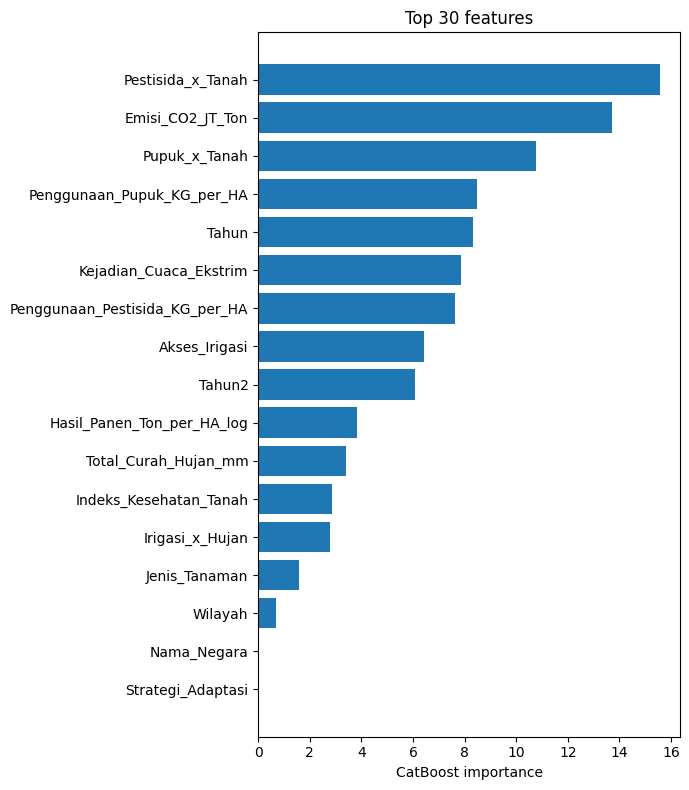

In [35]:
# ==============================
# Cell 17: Feature Importance (CatBoost)
# ==============================
from catboost import Pool
imps = None
for m in models_cb:
    imp = m.get_feature_importance(Pool(X, y, cat_features=[X.columns.get_loc(c) for c in cat_cols if c in X.columns]), type="FeatureImportance")
    imps = imp if imps is None else (imps + imp)
imps = imps / len(models_cb)

imp_df = pd.DataFrame({"feature": X.columns, "importance": imps}).sort_values("importance", ascending=False).head(30)
plt.figure(figsize=(7,8))
plt.barh(imp_df["feature"][::-1], imp_df["importance"][::-1])
plt.xlabel("CatBoost importance")
plt.title("Top 30 features")
plt.tight_layout(); plt.show()